In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv('/content/retail_sales_synthetic_10000.csv')

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (10000, 10)


,order_id,order_date,product_id,product_name,category,quantity,unit_price,sales_amount,city,payment_method
0,ORD0000001,2025-09-21,PGRO001,Rice 5kg,Grocery,2,363.41,726.82,Mumbai,UPI
1,ORD0000002,2025-05-25,PFUR002,Study Table,Furniture,1,6036.30,6036.30,Mumbai,Cash
2,ORD0000003,2025-07-05,PSPO001,Skipping Rope,Sports,3,243.66,730.99,Nagpur,Cash
3,ORD0000004,2025-04-07,PGRO003,Coffee 200g,Grocery,5,280.09,1400.44,Pune,Cash
4,ORD0000005,2025-03-01,PCLO001,T-Shirt,Clothing,5,120.50,602.50,Bengaluru,Net Banking


In [3]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nCategory Distribution:")
print(df['category'].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        10000 non-null  object 
 1   order_date      10000 non-null  object 
 2   product_id      10000 non-null  object 
 3   product_name    10000 non-null  object 
 4   category        10000 non-null  object 
 5   quantity        10000 non-null  int64  
 6   unit_price      10000 non-null  float64
 7   sales_amount    10000 non-null  float64
 8   city            10000 non-null  object 
 9   payment_method  10000 non-null  object 
dtypes: float64(2), int64(1), object(7)
memory usage: 781.4+ KB

Missing Values:
order_id          0
order_date        0
product_id        0
product_name      0
category          0
quantity          0
unit_price        0
sales_amount      0
city              0
payment_method    0
dtype: int64

Category Distribution:
category
Clot

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    StackingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
# Convert date into datetime
df['order_date'] = pd.to_datetime(df['order_date'])

# Extract month and day
df['order_month'] = df['order_date'].dt.month
df['order_day'] = df['order_date'].dt.day

# Remove unnecessary columns
df = df.drop(columns=[
    'order_id',
    'product_id',
    'product_name',
    'order_date'
])

# Separate features and target
X = df.drop('category', axis=1)
y = df['category']

# Identify numerical and categorical columns
numerical_cols = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_cols = X.select_dtypes(
    include=['object']
).columns.tolist()

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ), categorical_cols)
    ],
    sparse_threshold=0
)

# Split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Fit on training data and transform both datasets
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

print("Preprocessing completed!")
print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])
print("Training Features:", X_train.shape[1])

Preprocessing completed!
Training Samples: 8000
Testing Samples: 2000
Training Features: 14


In [6]:
svm = SVC(
    kernel='rbf',
    probability=True,
    random_state=42
)

dt = DecisionTreeClassifier(
    random_state=42
)

knn = KNeighborsClassifier(
    n_neighbors=5
)

nb = GaussianNB()

models = {
    "SVM": svm,
    "Decision Tree": dt,
    "KNN": knn,
    "Naive Bayes": nb
}

print("Base classifiers initialized successfully!")

Base classifiers initialized successfully!


In [7]:
base_predictions = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    base_predictions[name] = y_pred

    print(name, "trained successfully!")

SVM trained successfully!
Decision Tree trained successfully!
KNN trained successfully!
Naive Bayes trained successfully!


In [8]:
estimators = [
    ('svm', SVC(
        probability=True,
        random_state=42
    )),

    ('dt', DecisionTreeClassifier(
        random_state=42
    )),

    ('knn', KNeighborsClassifier(
        n_neighbors=5
    )),

    ('nb', GaussianNB())
]

stacking_model = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(
        max_iter=1000
    ),
    cv=5
)

stacking_model.fit(X_train, y_train)

stacking_pred = stacking_model.predict(X_test)

print("STACKING ENSEMBLE RESULTS")

print(classification_report(
    y_test,
    stacking_pred
))

STACKING ENSEMBLE RESULTS
              precision    recall  f1-score   support

    Clothing       0.62      0.66      0.64       407
 Electronics       0.58      0.53      0.55       400
   Furniture       0.85      0.84      0.84       403
     Grocery       0.82      0.89      0.86       399
      Sports       0.50      0.47      0.49       391

    accuracy                           0.68      2000
   macro avg       0.67      0.68      0.68      2000
weighted avg       0.67      0.68      0.68      2000



In [9]:
weak_learner = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

adaboost_model = AdaBoostClassifier(
    estimator=weak_learner,
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

adaboost_model.fit(X_train, y_train)

adaboost_pred = adaboost_model.predict(X_test)

print("ADABOOST ENSEMBLE RESULTS")

print(classification_report(
    y_test,
    adaboost_pred
))

ADABOOST ENSEMBLE RESULTS
              precision    recall  f1-score   support

    Clothing       0.45      0.78      0.57       407
 Electronics       0.30      0.25      0.27       400
   Furniture       0.77      0.79      0.78       403
     Grocery       0.71      0.98      0.82       399
      Sports       0.00      0.00      0.00       391

    accuracy                           0.56      2000
   macro avg       0.45      0.56      0.49      2000
weighted avg       0.45      0.56      0.49      2000



In [10]:
hard_voting = VotingClassifier(
    estimators=[
        ('svm', SVC(
            probability=True,
            random_state=42
        )),

        ('dt', DecisionTreeClassifier(
            random_state=42
        )),

        ('knn', KNeighborsClassifier(
            n_neighbors=5
        )),

        ('nb', GaussianNB())
    ],
    voting='hard'
)

hard_voting.fit(X_train, y_train)

hard_pred = hard_voting.predict(X_test)

print("HARD VOTING RESULTS")

print(classification_report(
    y_test,
    hard_pred
))

HARD VOTING RESULTS
              precision    recall  f1-score   support

    Clothing       0.54      0.77      0.63       407
 Electronics       0.56      0.47      0.51       400
   Furniture       0.90      0.80      0.85       403
     Grocery       0.80      0.91      0.85       399
      Sports       0.50      0.34      0.40       391

    accuracy                           0.66      2000
   macro avg       0.66      0.66      0.65      2000
weighted avg       0.66      0.66      0.65      2000



In [11]:
soft_voting = VotingClassifier(
    estimators=[
        ('svm', SVC(
            probability=True,
            random_state=42
        )),

        ('dt', DecisionTreeClassifier(
            random_state=42
        )),

        ('knn', KNeighborsClassifier(
            n_neighbors=5
        )),

        ('nb', GaussianNB())
    ],
    voting='soft'
)

soft_voting.fit(X_train, y_train)

soft_pred = soft_voting.predict(X_test)

print("SOFT VOTING RESULTS")

print(classification_report(
    y_test,
    soft_pred
))

SOFT VOTING RESULTS
              precision    recall  f1-score   support

    Clothing       0.60      0.64      0.62       407
 Electronics       0.59      0.48      0.53       400
   Furniture       0.89      0.83      0.86       403
     Grocery       0.79      0.93      0.85       399
      Sports       0.50      0.51      0.51       391

    accuracy                           0.68      2000
   macro avg       0.68      0.68      0.67      2000
weighted avg       0.68      0.68      0.68      2000



In [12]:
all_models = {
    "SVM": svm,
    "Decision Tree": dt,
    "KNN": knn,
    "Naive Bayes": nb,
    "Stacking": stacking_model,
    "AdaBoost": adaboost_model,
    "Hard Voting": hard_voting,
    "Soft Voting": soft_voting
}

results = []

for name, model in all_models.items():

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average='weighted',
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average='weighted',
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average='weighted',
        zero_division=0
    )

    if hasattr(model, 'predict_proba'):

        y_prob = model.predict_proba(X_test)

        loss = log_loss(
            y_test,
            y_prob,
            labels=model.classes_
        )

    else:
        loss = np.nan

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'Log Loss': loss
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='Accuracy',
    ascending=False
)

print("COMPARATIVE PERFORMANCE RESULTS")

display(results_df.round(4))

COMPARATIVE PERFORMANCE RESULTS


,Model,Accuracy,Precision,Recall,F1-Score,Log Loss
4,Stacking,0.6795,0.6745,0.6795,0.6761,0.7298
7,Soft Voting,0.6790,0.6763,0.6790,0.6750,0.7818
6,Hard Voting,0.6595,0.6589,0.6595,0.6498,NaN
1,Decision Tree,0.6450,0.6474,0.6450,0.6462,12.7955
0,SVM,0.6240,0.6296,0.6240,0.6214,0.8505
2,KNN,0.6230,0.6139,0.6230,0.6162,3.6232
5,AdaBoost,0.5645,0.4486,0.5645,0.4927,1.5694
3,Naive Bayes,0.5120,0.4745,0.5120,0.4787,1.3610


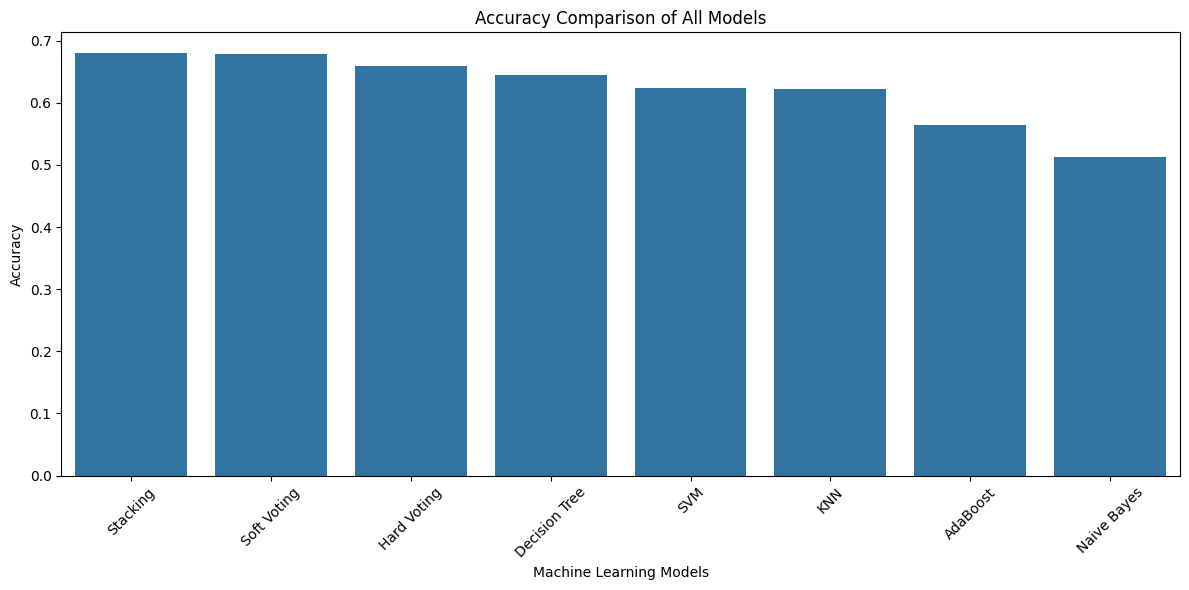

In [13]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy'
)

plt.title('Accuracy Comparison of All Models')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

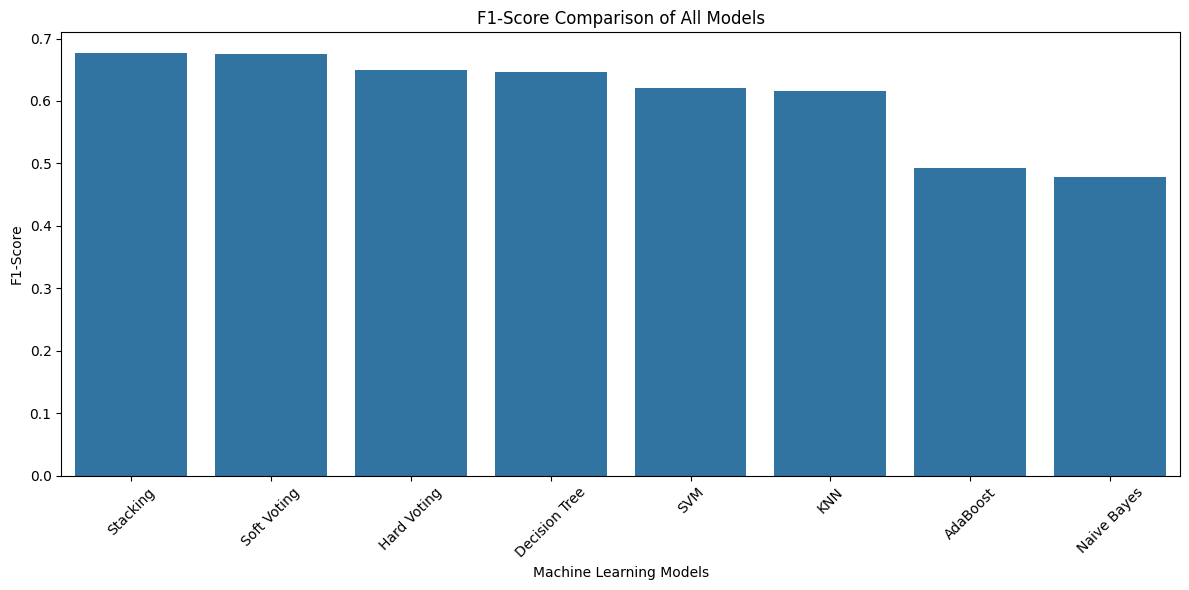

In [14]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='F1-Score'
)

plt.title('F1-Score Comparison of All Models')
plt.xlabel('Machine Learning Models')
plt.ylabel('F1-Score')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

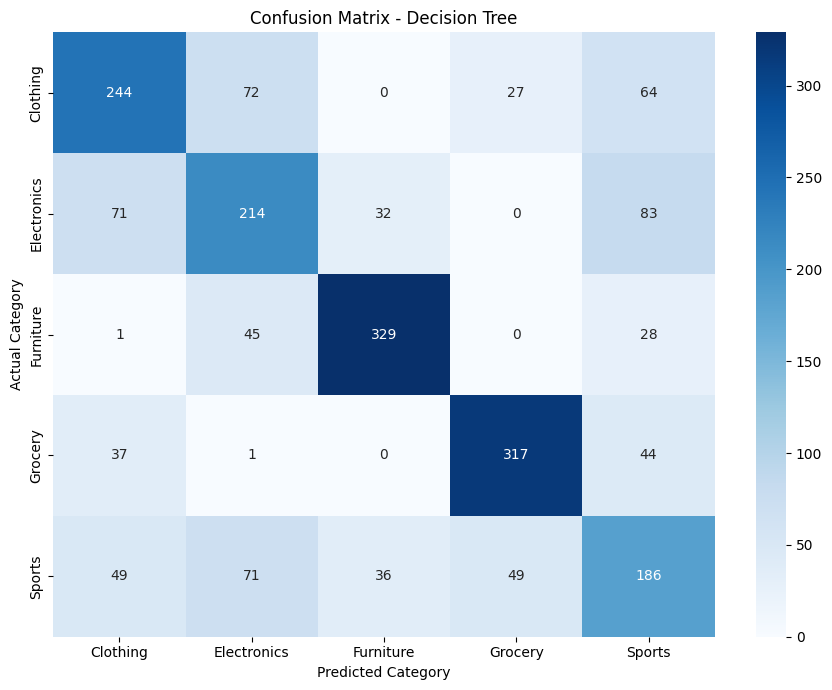

In [15]:
dt_pred = dt.predict(X_test)

cm = confusion_matrix(
    y_test,
    dt_pred,
    labels=dt.classes_
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=dt.classes_,
    yticklabels=dt.classes_
)

plt.title('Confusion Matrix - Decision Tree')
plt.xlabel('Predicted Category')
plt.ylabel('Actual Category')

plt.tight_layout()
plt.show()

In [16]:
results_df.to_csv(
    'ensemble_comparison_results.csv',
    index=False
)

print("Results saved successfully!")

Results saved successfully!


In [17]:
from google.colab import files

files.download(
    'ensemble_comparison_results.csv'
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>